# Optimizers from Scratch: SGD, Momentum, Nesterov, AdaGrad, RMSProp, Adam, AdamW

This notebook implements seven gradient-based optimizers **from scratch** as subclasses of `torch.optim.Optimizer`.
It only uses PyTorch for automatic differentiation, never for the update rules. Then it:

1. **Checks** that each implementation matches PyTorch's built-in optimizer step for step.
2. **Compares** the optimizers on a 2D loss landscape with one global minimum and three local minima.
3. **Runs experiments** from a grid of 441 starting points and a range of learning rates, measuring how often each optimizer
   reaches the global minimum, gets trapped in a local minimum, or stalls on a flat region, and how fast it converges.

All updates are element-wise, so a batch of N starting points can be optimized at once as one `(N, 2)` parameter tensor.
Each point follows exactly the path it would follow on its own.

In [1]:
import math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go

torch.manual_seed(0)
pd.set_option("display.precision", 3)

## 1. The loss landscape

The loss is a sum of inverted Gaussians:

$$
L(x, y) = A_g \exp\!\left(-\frac{(x-x_g)^2 + (y-y_g)^2}{2\sigma_g^2}\right) + \sum_{k} A_k \exp\!\left(-\frac{(x-x_k)^2 + (y-y_k)^2}{2\sigma_k^2}\right)
$$

- **Global minimum:** depth $A_g=-10$, width $\sigma_g=2$, at $(0, 0)$.
- **Local minima:** $(A, \sigma, x, y) = (-5, 1, 3, 3),\ (-7, 1.5, -4, -4),\ (-4, 0.8, -2, 5)$.

Far from every Gaussian, the surface is almost perfectly **flat**, so the gradient is close to zero.
That makes it a good test of how each optimizer handles plateaus as well as local minima.

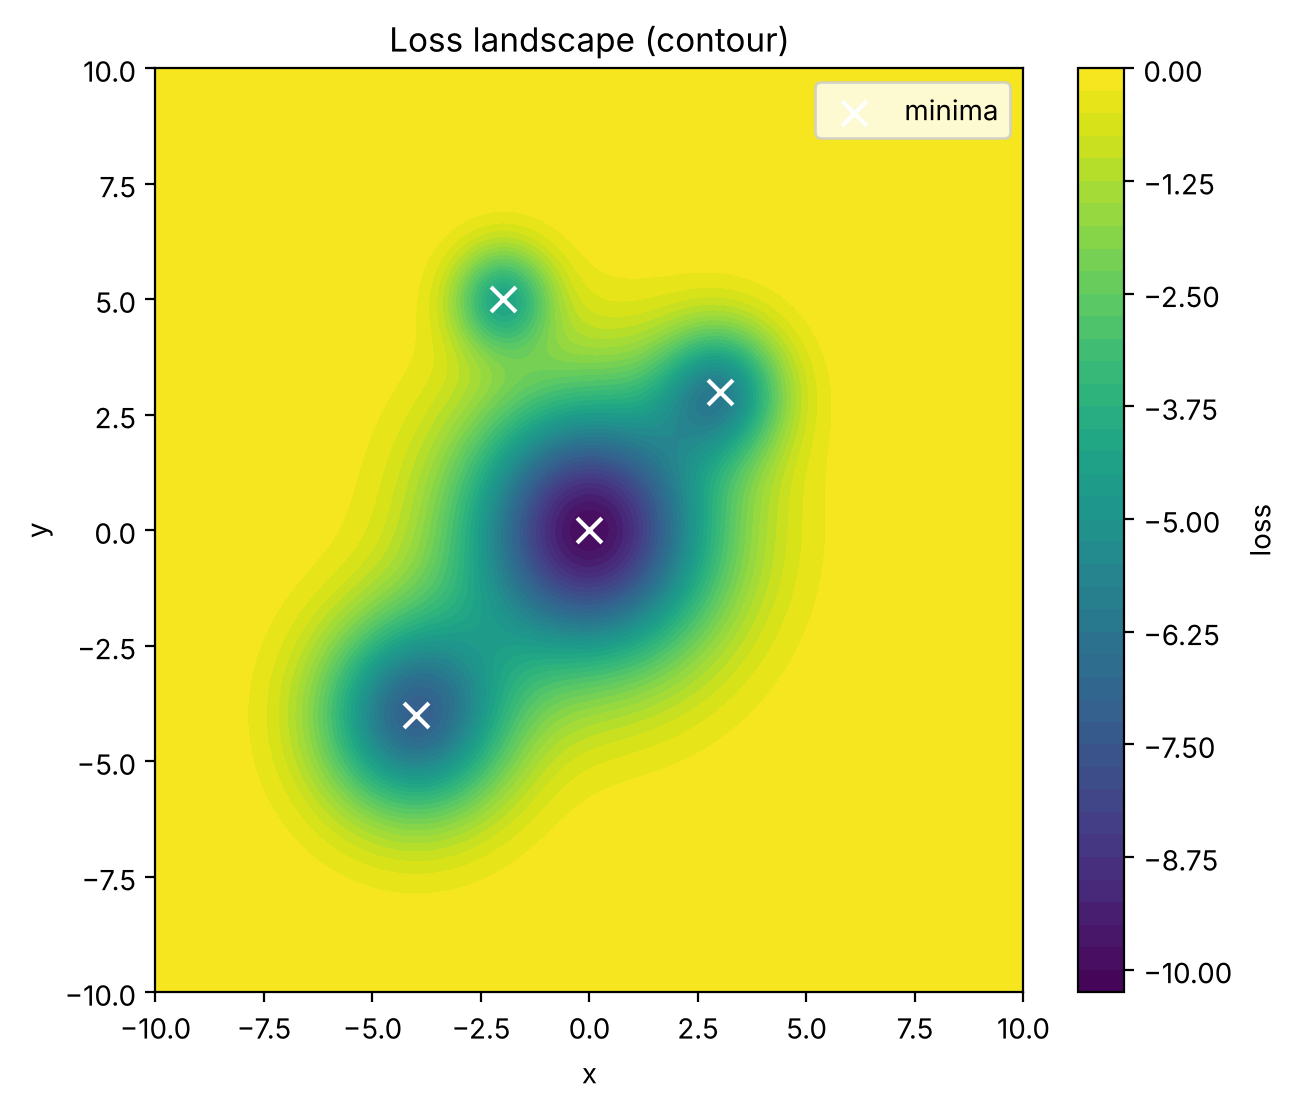

In [2]:
class LossTerrain:
    def __init__(self, A_g=-10.0, sigma_g=2.0, global_min=(0.0, 0.0),
                 local_minima=((-5, 1, 3, 3), (-7, 1.5, -4, -4), (-4, 0.8, -2, 5))):
        self.A_g, self.sigma_g, self.global_min = A_g, sigma_g, global_min
        self.local_minima = local_minima
        # Centers used to label which basin a point ended in (0 = global, 1..k = local)
        self.centers = torch.tensor([global_min] + [(x, y) for _, _, x, y in local_minima], dtype=torch.float64)
        self.names = ["global (0,0)"] + [f"local ({x},{y})" for _, _, x, y in local_minima]

    def __call__(self, P):
        # P has shape (..., 2); returns the loss at each point
        x, y = P[..., 0], P[..., 1]
        gx, gy = self.global_min
        Z = self.A_g * torch.exp(-((x - gx) ** 2 + (y - gy) ** 2) / (2 * self.sigma_g ** 2))
        for A, s, cx, cy in self.local_minima:
            Z = Z + A * torch.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * s ** 2))
        return Z

    def basin(self, P, radius=1.0):
        # Label the minimum each point ended near; -1 means it stalled away from every minimum
        d = torch.cdist(P.to(torch.float64), self.centers)
        dmin, idx = d.min(dim=1)
        return torch.where(dmin < radius, idx, torch.full_like(idx, -1))

terrain = LossTerrain()

xs = torch.linspace(-10, 10, 300, dtype=torch.float64)
GX, GY = torch.meshgrid(xs, xs, indexing="xy")
GZ = terrain(torch.stack([GX, GY], dim=-1))

fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contourf(GX, GY, GZ, levels=40, cmap="viridis")
plt.colorbar(cs, ax=ax, label="loss")
ax.scatter(*terrain.centers.T, c="white", marker="x", s=80, label="minima")
ax.set_title("Loss landscape (contour)"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
plt.show()

## 2. Optimizers from scratch

Notation: $\theta$ = parameters, $g_t = \nabla L(\theta_t)$, $\eta$ = learning rate. All operations are element-wise.

| Optimizer | Update rule |
|---|---|
| **SGD** | $\theta \leftarrow \theta - \eta\, g_t$ |
| **Momentum** (heavy ball) | $b_t = \mu b_{t-1} + g_t,\quad \theta \leftarrow \theta - \eta\, b_t$ |
| **Nesterov** | $b_t = \mu b_{t-1} + g_t,\quad \theta \leftarrow \theta - \eta\,(g_t + \mu b_t)$ |
| **AdaGrad** | $G_t = G_{t-1} + g_t^2,\quad \theta \leftarrow \theta - \eta\, g_t / (\sqrt{G_t} + \epsilon)$ |
| **RMSProp** | $v_t = \alpha v_{t-1} + (1-\alpha) g_t^2,\quad \theta \leftarrow \theta - \eta\, g_t / (\sqrt{v_t} + \epsilon)$ |
| **Adam** | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\ v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,\ \hat m_t = \frac{m_t}{1-\beta_1^t},\ \hat v_t = \frac{v_t}{1-\beta_2^t},\ \theta \leftarrow \theta - \eta\, \hat m_t / (\sqrt{\hat v_t} + \epsilon)$ |
| **AdamW** | $\theta \leftarrow \theta(1 - \eta\lambda)$, then the Adam step (weight decay applied directly to the weights, separate from the gradient) |

**Intuition:**
- **Momentum** builds up velocity in directions where the gradient stays consistent, which helps it roll through small bumps.
- **AdaGrad, RMSProp and Adam** divide by a running size of the gradient, so each coordinate takes steps of roughly size $\eta$ whether the gradient is tiny or huge. That lets them keep moving on flat regions where plain SGD stalls.
- **Adam's bias correction** fixes the fact that $m$ and $v$ start at zero, which would otherwise make the first steps too small.

In [3]:
class ScratchOptimizer(torch.optim.Optimizer):
    # Shared loop: subclasses only implement `update`, which receives one parameter, its gradient,
    # its persistent state dict, and the hyperparameters for its group.
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is not None:
                    self.update(p, p.grad, self.state[p], group)
        return loss

    def update(self, p, g, state, group):
        raise NotImplementedError


class SGD(ScratchOptimizer):
    def __init__(self, params, lr=0.01):
        super().__init__(params, dict(lr=lr))

    def update(self, p, g, state, group):
        p -= group["lr"] * g


class Momentum(ScratchOptimizer):
    def __init__(self, params, lr=0.01, momentum=0.9, nesterov=False):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov))

    def update(self, p, g, state, group):
        mu = group["momentum"]
        if "b" not in state:
            state["b"] = torch.zeros_like(p)
        b = state["b"]
        b.mul_(mu).add_(g)                     # b_t = mu * b_{t-1} + g_t
        direction = g + mu * b if group["nesterov"] else b
        p -= group["lr"] * direction


class Nesterov(Momentum):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params, lr=lr, momentum=momentum, nesterov=True)


class AdaGrad(ScratchOptimizer):
    def __init__(self, params, lr=0.01, eps=1e-10):
        super().__init__(params, dict(lr=lr, eps=eps))

    def update(self, p, g, state, group):
        if "G" not in state:
            state["G"] = torch.zeros_like(p)
        G = state["G"]
        G += g * g                             # running sum of squared gradients
        p -= group["lr"] * g / (G.sqrt() + group["eps"])


class RMSProp(ScratchOptimizer):
    def __init__(self, params, lr=0.01, alpha=0.99, eps=1e-8):
        super().__init__(params, dict(lr=lr, alpha=alpha, eps=eps))

    def update(self, p, g, state, group):
        a = group["alpha"]
        if "v" not in state:
            state["v"] = torch.zeros_like(p)
        v = state["v"]
        v.mul_(a).add_((1 - a) * g * g)        # exponential moving average of g^2
        p -= group["lr"] * g / (v.sqrt() + group["eps"])


class Adam(ScratchOptimizer):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, decoupled=False):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, decoupled=decoupled))

    def update(self, p, g, state, group):
        b1, b2 = group["betas"]
        lr, eps, wd = group["lr"], group["eps"], group["weight_decay"]
        if "t" not in state:
            state["t"], state["m"], state["v"] = 0, torch.zeros_like(p), torch.zeros_like(p)
        if group["decoupled"] and wd != 0:
            p.mul_(1 - lr * wd)                # AdamW: shrink the weights directly
        state["t"] += 1
        t, m, v = state["t"], state["m"], state["v"]
        m.lerp_(g, 1 - b1)                     # 1st moment: m = b1*m + (1-b1)*g
        v.mul_(b2).addcmul_(g, g, value=1 - b2)  # 2nd moment: v = b2*v + (1-b2)*g^2
        bc1, bc2 = 1 - b1 ** t, 1 - b2 ** t    # bias corrections
        # Same as lr * m_hat / (sqrt(v_hat) + eps), written in PyTorch's operation order
        denom = v.sqrt() / math.sqrt(bc2) + eps
        p.addcdiv_(m, denom, value=-lr / bc1)


class AdamW(Adam):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        super().__init__(params, lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, decoupled=True)


SCRATCH = {"SGD": SGD, "Momentum": Momentum, "Nesterov": Nesterov, "AdaGrad": AdaGrad,
           "RMSProp": RMSProp, "Adam": Adam, "AdamW": AdamW}

## 3. Check against PyTorch's built-in optimizers

Each from-scratch optimizer and its `torch.optim` counterpart start from the same 64 random points and take 1,000 steps on the landscape, in float64.
If the math is right, the paths should match to within floating-point rounding.

In [4]:
TORCH = {
    "SGD":      (torch.optim.SGD,     dict(lr=0.1)),
    "Momentum": (torch.optim.SGD,     dict(lr=0.05, momentum=0.9)),
    "Nesterov": (torch.optim.SGD,     dict(lr=0.05, momentum=0.9, nesterov=True)),
    "AdaGrad":  (torch.optim.Adagrad, dict(lr=0.1)),
    "RMSProp":  (torch.optim.RMSprop, dict(lr=0.01)),
    "Adam":     (torch.optim.Adam,    dict(lr=0.05)),
    "AdamW":    (torch.optim.AdamW,   dict(lr=0.05, weight_decay=0.01)),
}
SCRATCH_ARGS = {name: {k: v for k, v in args.items() if k != "nesterov"} for name, (_, args) in TORCH.items()}

def run_path(opt_cls, start, steps, **kwargs):
    # Optimize a batch of starting points; returns the full path, shape (steps + 1, N, 2)
    P = torch.nn.Parameter(start.clone())
    opt = opt_cls([P], **kwargs)
    path = [P.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        terrain(P).sum().backward()            # summing keeps each point's gradient independent
        opt.step()
        path.append(P.detach().clone())
    return torch.stack(path)

start = (torch.rand(64, 2, dtype=torch.float64) - 0.5) * 16
rows = []
for name, (torch_cls, args) in TORCH.items():
    ours = run_path(SCRATCH[name], start, 1000, **SCRATCH_ARGS[name])
    ref = run_path(torch_cls, start, 1000, foreach=False, **args)
    rows.append({"optimizer": name, "hyperparameters": args,
                 "max |difference| over 1,000 steps": (ours - ref).abs().max().item()})
check = pd.DataFrame(rows)
check["matches PyTorch"] = check["max |difference| over 1,000 steps"] < 1e-8
check

,optimizer,hyperparameters,"max |difference| over 1,000 steps",matches PyTorch
0,SGD,{'lr': 0.1},1.341e-13,True
1,Momentum,"{'lr': 0.05, 'momentum': 0.9}",2.087e-14,True
2,Nesterov,"{'lr': 0.05, 'momentum': 0.9, 'nesterov': True}",1.150e-13,True
3,AdaGrad,{'lr': 0.1},3.109e-15,True
4,RMSProp,{'lr': 0.01},3.520e-15,True
5,Adam,{'lr': 0.05},0.000e+00,True
6,AdamW,"{'lr': 0.05, 'weight_decay': 0.01}",0.000e+00,True


## 4. Paths from one starting point

All seven optimizers start from $(1.9, -2.9)$, the default starting point in the original visualization, and run for 3,000 steps.
Each one uses the learning rate that worked best in the sweep in Section 5.

In [5]:
BEST_LR = {}  # filled in by the learning-rate sweep below; these defaults are used if you run this cell first
DEFAULT_LR = {"SGD": 0.3, "Momentum": 0.03, "Nesterov": 0.03, "AdaGrad": 0.3,
              "RMSProp": 0.01, "Adam": 0.03, "AdamW": 0.03}

def plot_paths(start_xy, steps=3000, lrs=None, title=None):
    lrs = lrs or DEFAULT_LR
    start = torch.tensor([start_xy], dtype=torch.float64)
    fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True)
    results = []
    for ax, name in zip(axes.flat, SCRATCH):
        path = run_path(SCRATCH[name], start, steps, lr=lrs[name])[:, 0]
        ax.contourf(GX, GY, GZ, levels=30, cmap="viridis")
        ax.plot(path[:, 0], path[:, 1], "r.-", ms=2, lw=1)
        ax.plot(*path[0], "wo", ms=7); ax.plot(*path[-1], "r*", ms=14)
        final = path[-1]
        b = outcome(path[:, None])[0].item()
        where = terrain.names[b] if b >= 0 else ("stalled (flat region)" if b == -1 else "not settled")
        ax.set_title(f"{name} (lr={lrs[name]})\nended: {where}", fontsize=10)
        results.append({"optimizer": name, "lr": lrs[name], "final x": final[0].item(), "final y": final[1].item(),
                        "final loss": terrain(final).item(), "ended in": where})
    axes.flat[-1].axis("off")
    fig.suptitle(title or f"Optimizer paths from {start_xy}", fontsize=14)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(results)

## 5. Experiment: 441 starting points × 7 learning rates

Starting points form a 21 × 21 grid over $[-8, 8]^2$. Each run takes 3,000 steps.
A run has **settled** if it stays within 0.01 of its final position for the last 500 steps. Each run gets one outcome:

- **Global:** settled within 1.0 of $(0, 0)$.
- **Local:** settled within 1.0 of one of the local minima.
- **Stalled:** settled somewhere else. This is almost always a nearly flat region where the gradient is close to zero.
- **Not settled:** still moving after 3,000 steps. Either it's bouncing around a minimum because the learning rate is too large, or it's creeping very slowly across a flat region.

**Steps to converge** is the first step after which the point stays within 0.01 of where it finishes. It's only reported for runs that settled in the global minimum.

In [6]:
LRS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
STEPS = 3000
g = torch.linspace(-8, 8, 21, dtype=torch.float64)
GRID = torch.stack(torch.meshgrid(g, g, indexing="xy"), dim=-1).reshape(-1, 2)

def outcome(path, tol=0.01, window=500):
    # 0 = global, 1..k = local, -1 = stalled on a flat region, -2 = not settled (still moving)
    settled = (path[-window:] - path[-1]).norm(dim=-1).max(dim=0).values < tol
    return torch.where(settled, terrain.basin(path[-1]), torch.full((path.shape[1],), -2))

def steps_to_converge(path, tol=0.01):
    # path: (T+1, N, 2). First step t such that the point stays within tol of its final position from t onward.
    dist = (path - path[-1]).norm(dim=-1)                       # (T+1, N)
    far = dist >= tol
    any_far_after = torch.flip(torch.cummax(torch.flip(far.int(), [0]), dim=0).values, [0]).bool()
    return (~any_far_after).int().argmax(dim=0)                 # first index where it's never far again

records = []
for name, cls in SCRATCH.items():
    for lr in LRS:
        path = run_path(cls, GRID, STEPS, lr=lr)
        final = path[-1]
        if not torch.isfinite(final).all():
            records.append({"optimizer": name, "lr": lr, "global %": np.nan, "local %": np.nan,
                            "stalled %": np.nan, "not settled %": np.nan,
                            "median steps (global runs)": np.nan, "diverged": True})
            continue
        out = outcome(path)
        conv = steps_to_converge(path)
        hit = out == 0
        pct = lambda mask: 100 * mask.double().mean().item()
        records.append({
            "optimizer": name, "lr": lr,
            "global %": pct(hit), "local %": pct(out > 0),
            "stalled %": pct(out == -1), "not settled %": pct(out == -2),
            "median steps (global runs)": conv[hit].double().median().item() if hit.any() else np.nan,
            "diverged": False,
        })

sweep = pd.DataFrame(records)
pivot = sweep.pivot(index="optimizer", columns="lr", values="global %").loc[list(SCRATCH)]
pivot

lr,0.001,0.003,0.010,0.030,0.100,0.300,1.000
optimizer,,,,,,,
SGD,9.297,25.397,31.293,36.054,40.363,43.991,0.000
Momentum,31.519,36.508,41.270,54.422,65.760,71.882,23.129
Nesterov,31.519,36.508,41.270,50.567,56.009,63.492,0.000
AdaGrad,1.134,0.227,0.227,3.855,36.735,36.735,39.002
RMSProp,5.669,35.828,18.141,20.408,11.565,0.000,0.000
Adam,2.041,36.735,36.735,37.415,38.322,49.433,8.163
AdamW,2.041,36.735,37.188,38.776,38.776,48.073,0.907


### Learning-rate sensitivity

Left: percentage of the 441 starting points that settle in the **global** minimum. Right: percentage still moving after 3,000 steps.
Pushing the learning rate up helps optimizers jump past local minima, but once it's too large they can't come to rest anywhere.

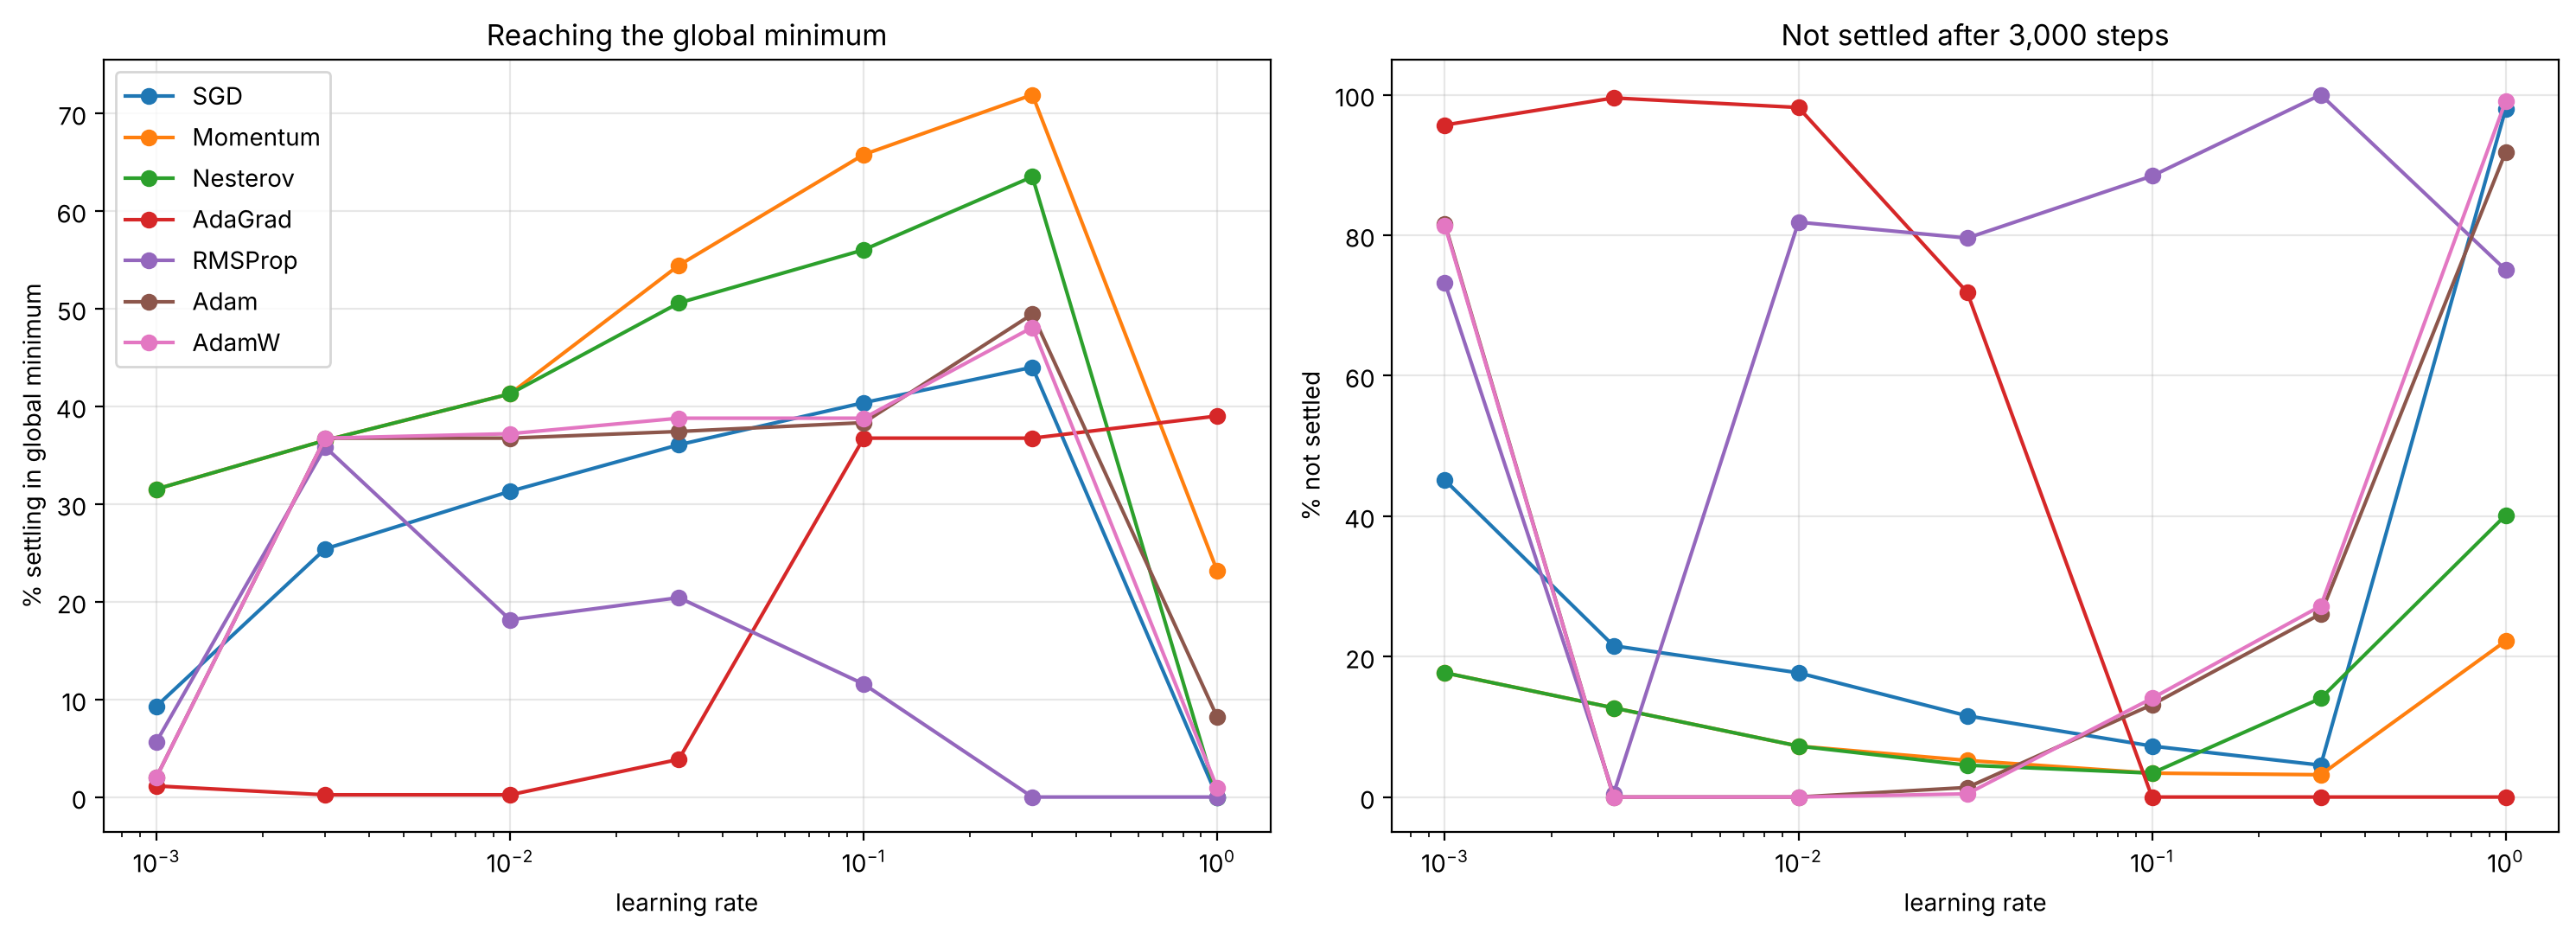

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
for name in SCRATCH:
    s = sweep[sweep.optimizer == name]
    ax1.plot(s.lr, s["global %"], "o-", label=name)
    ax2.plot(s.lr, s["not settled %"], "o-", label=name)
for ax, yl, t in [(ax1, "% settling in global minimum", "Reaching the global minimum"),
                  (ax2, "% not settled", "Not settled after 3,000 steps")]:
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel(yl); ax.set_title(t); ax.grid(alpha=0.3)
ax1.legend(); plt.tight_layout(); plt.show()

### Best learning rate for each optimizer

For each optimizer, this picks the learning rate with the highest global-minimum rate. Ties go to the fewer median steps.

In [8]:
best = (sweep.dropna(subset=["global %"])
             .sort_values(["global %", "median steps (global runs)"], ascending=[False, True])
             .groupby("optimizer").head(1).set_index("optimizer").loc[list(SCRATCH)])
BEST_LR = best["lr"].to_dict()
best[["lr", "global %", "local %", "stalled %", "not settled %", "median steps (global runs)"]]

,lr,global %,local %,stalled %,not settled %,median steps (global runs)
optimizer,,,,,,
SGD,0.300,43.991,48.073,3.401,4.535,14.0
Momentum,0.300,71.882,24.263,0.680,3.175,114.0
Nesterov,0.300,63.492,21.769,0.680,14.059,18.0
AdaGrad,1.000,39.002,60.998,0.000,0.000,12.0
RMSProp,0.003,35.828,63.719,0.000,0.454,1508.0
Adam,0.300,49.433,24.490,0.000,26.077,116.0
AdamW,0.300,48.073,24.717,0.000,27.211,113.0


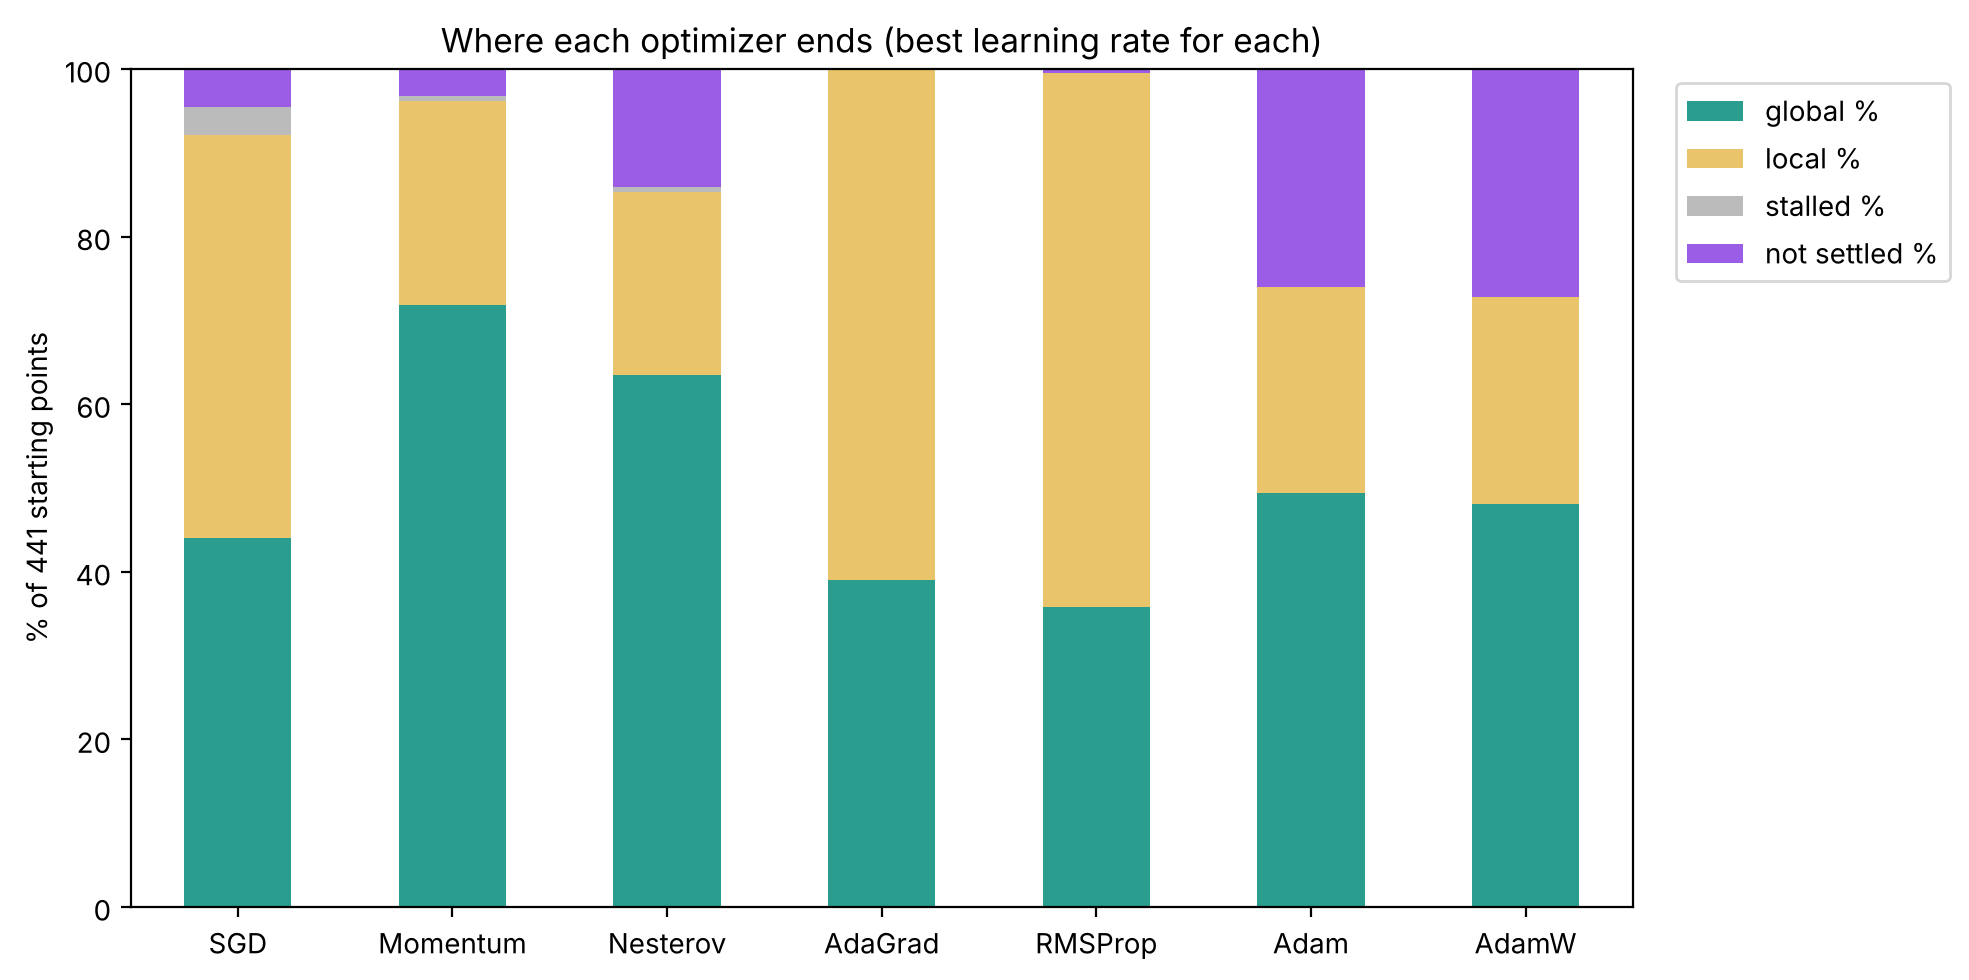

In [9]:
best_plot = best[["global %", "local %", "stalled %", "not settled %"]]
ax = best_plot.plot(kind="bar", stacked=True, figsize=(10, 5), color=["#2a9d8f", "#e9c46a", "#bbbbbb", "#9b5de5"])
ax.set_ylabel("% of 441 starting points"); ax.set_xlabel("")
ax.set_title("Where each optimizer ends (best learning rate for each)")
ax.legend(loc="upper right", bbox_to_anchor=(1.22, 1)); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Basin maps

Each pixel is one starting point, colored by where the optimizer ended up when using its best learning rate.
These maps show each optimizer's **basin of attraction** for the global minimum.

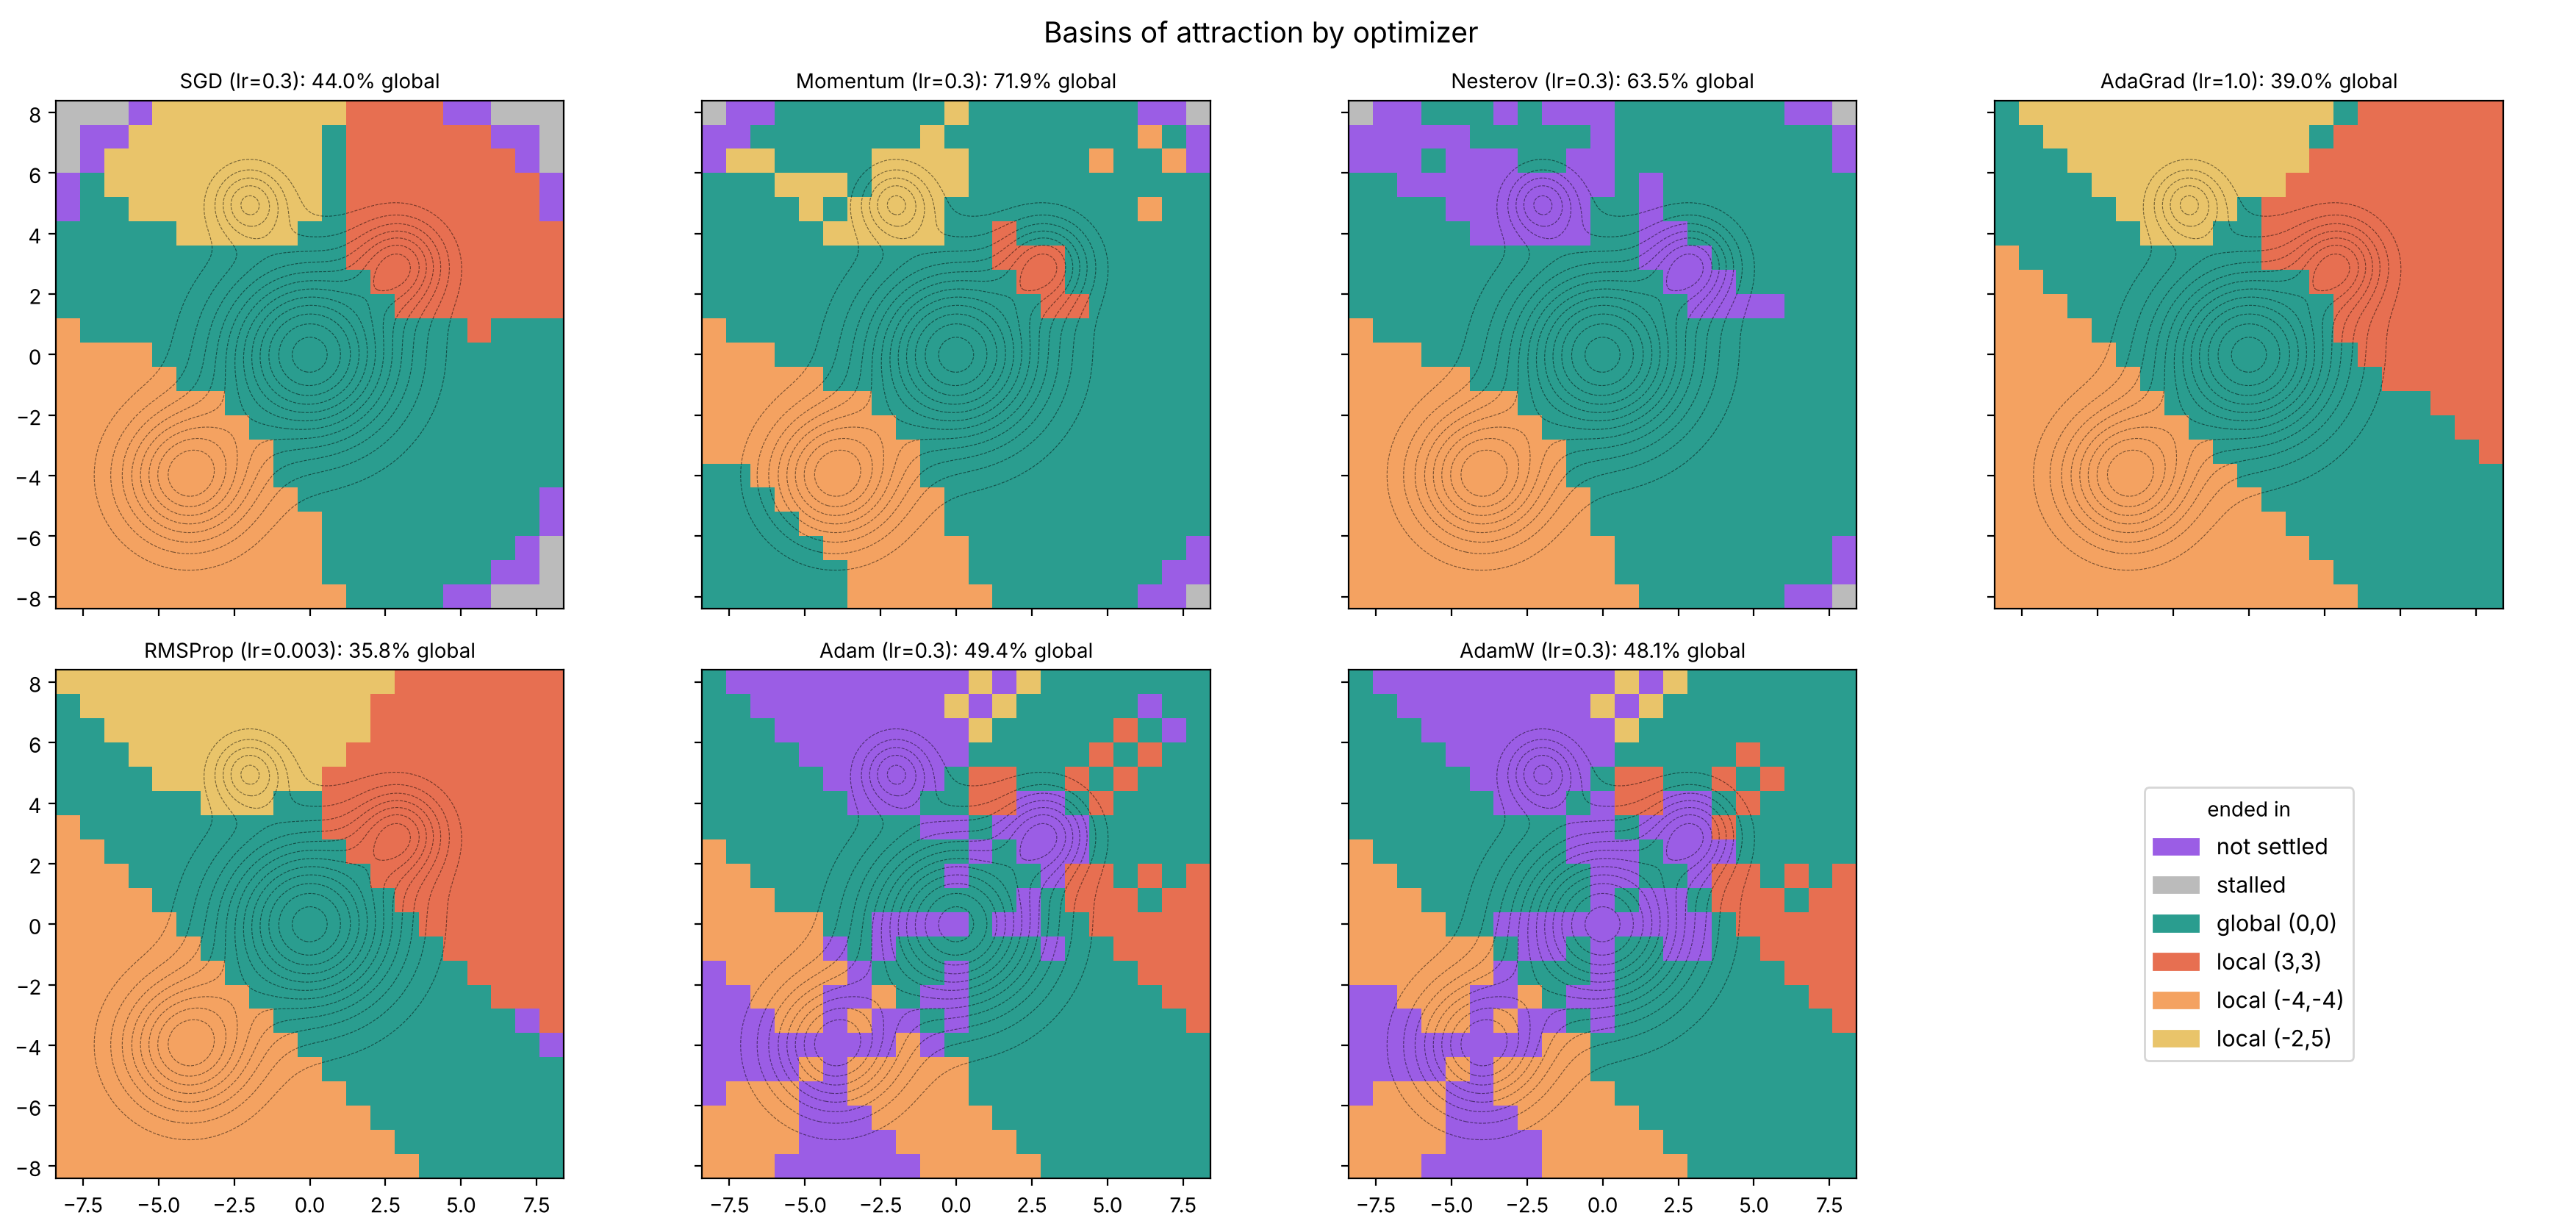

In [10]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#9b5de5", "#bbbbbb", "#2a9d8f", "#e76f51", "#f4a261", "#e9c46a"])  # not settled, stalled, global, 3 locals
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True)
for ax, name in zip(axes.flat, SCRATCH):
    path = run_path(SCRATCH[name], GRID, STEPS, lr=BEST_LR[name])
    lab = outcome(path).reshape(21, 21) + 2
    ax.imshow(lab.numpy(), origin="lower", extent=(-8.4, 8.4, -8.4, 8.4), cmap=cmap, vmin=0, vmax=5)
    ax.contour(GX, GY, GZ, levels=12, colors="k", linewidths=0.4, alpha=0.5)
    ax.set_xlim(-8.4, 8.4); ax.set_ylim(-8.4, 8.4)
    ax.set_title(f"{name} (lr={BEST_LR[name]}): {best.loc[name, 'global %']:.1f}% global", fontsize=10)
axes.flat[-1].axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors]
axes.flat[-1].legend(handles, ["not settled", "stalled"] + terrain.names, loc="center", fontsize=11, title="ended in")
plt.suptitle("Basins of attraction by optimizer", fontsize=14); plt.tight_layout(); plt.show()

## 6. Paths from specific starting points (best learning rates)

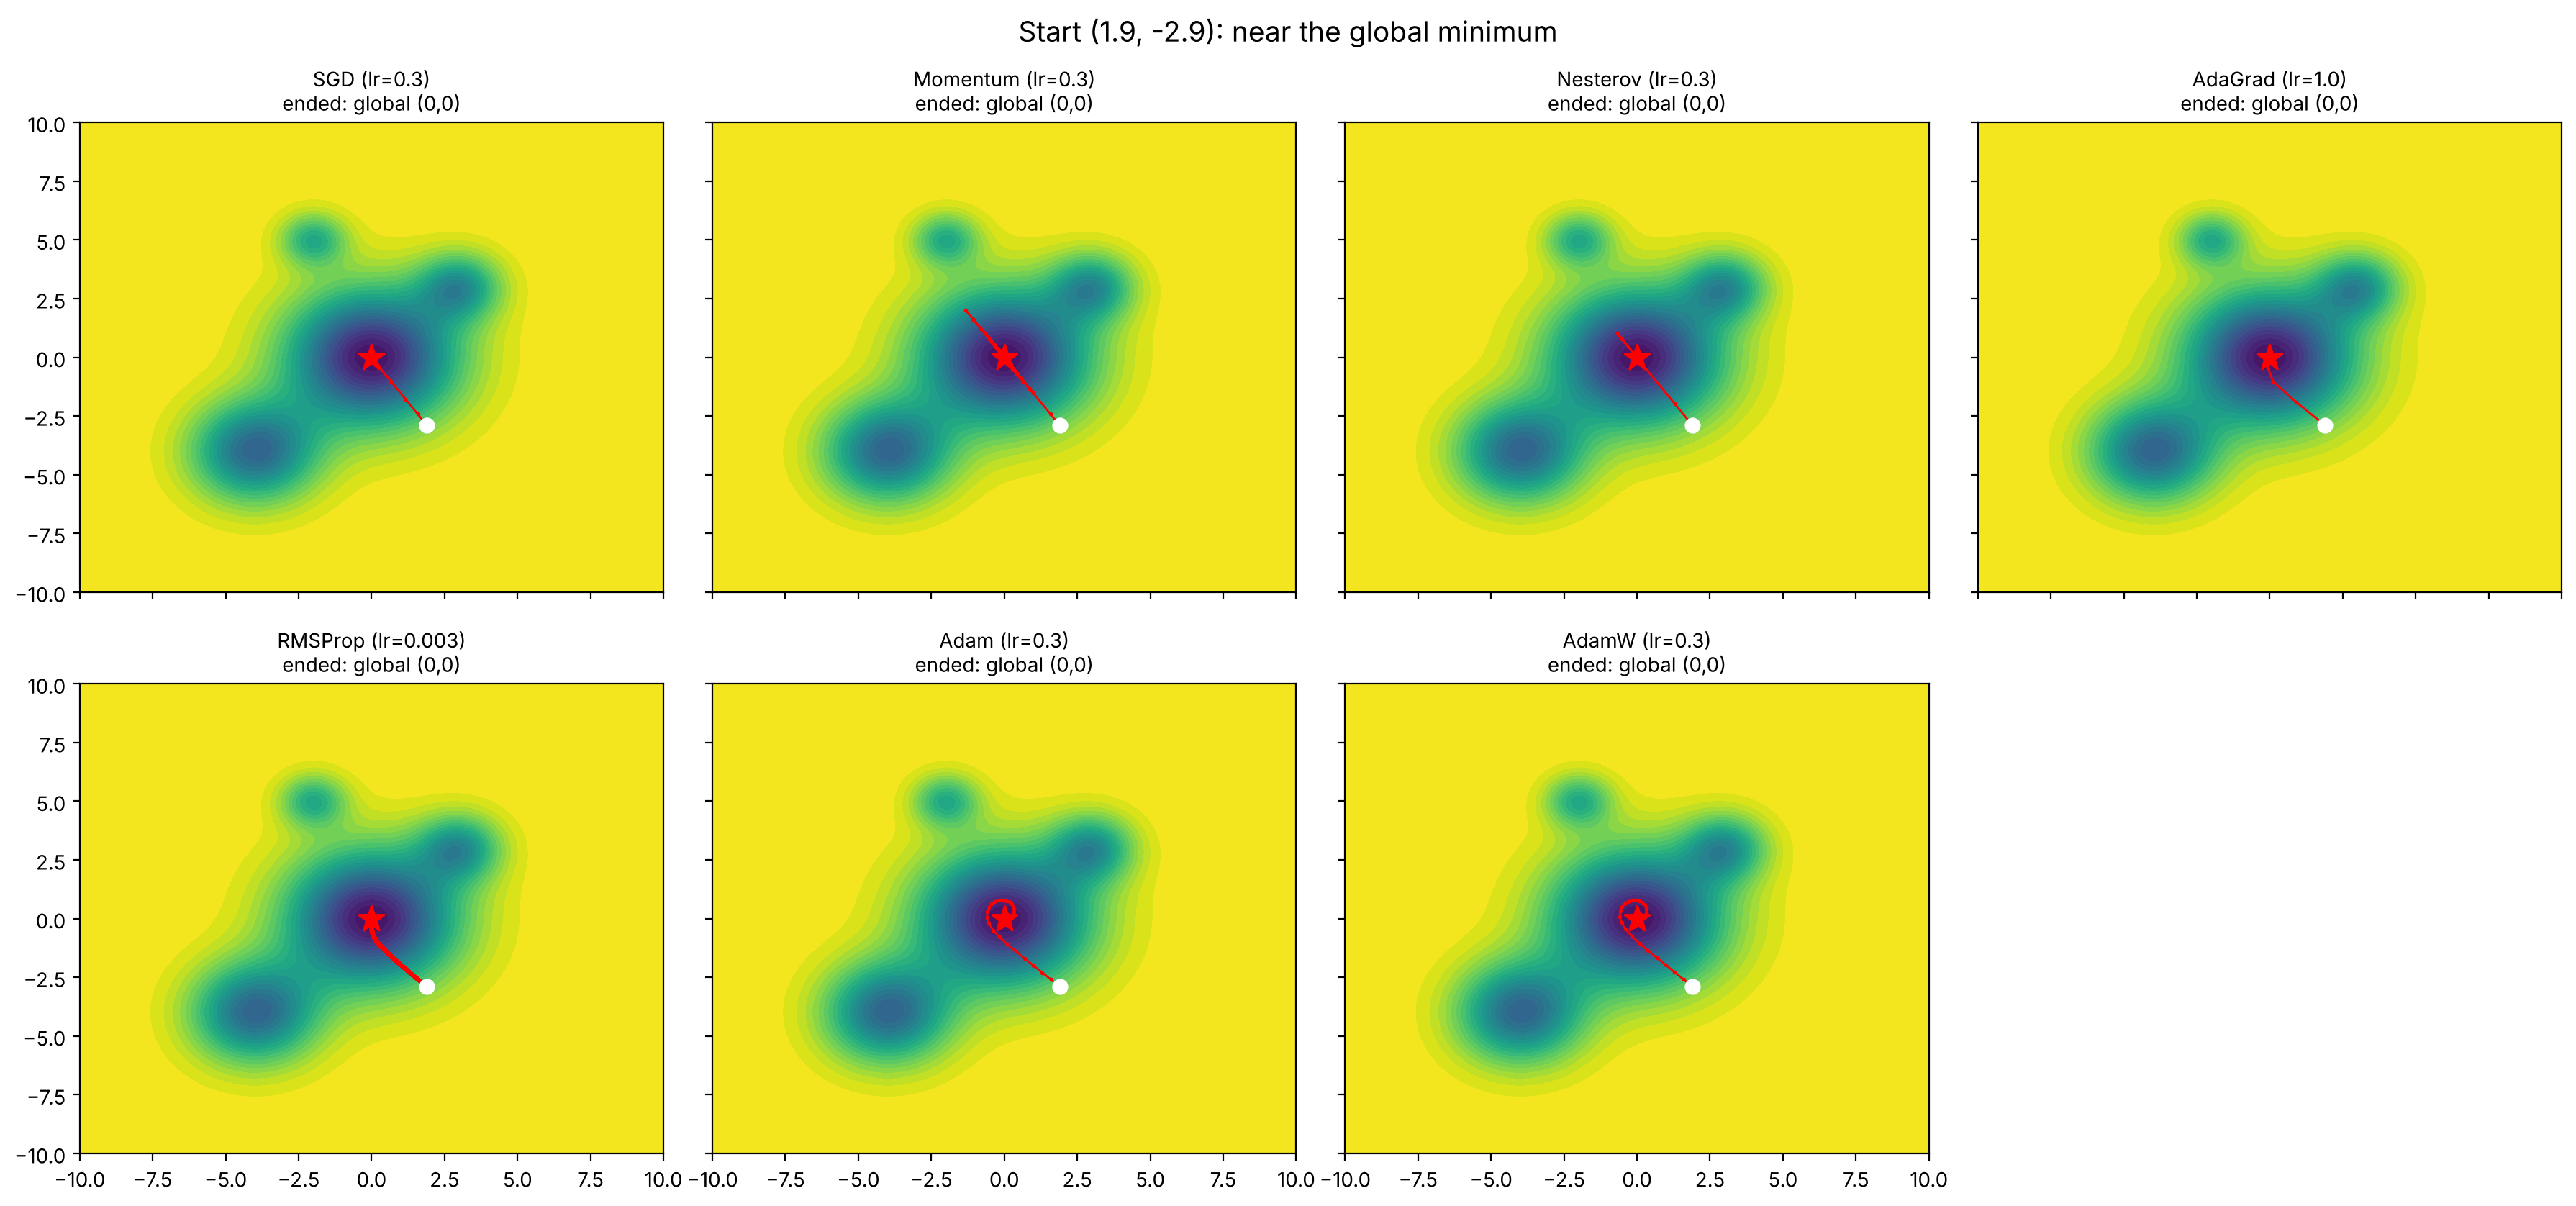

,optimizer,lr,final x,final y,final loss,ended in
0,SGD,0.300,-0.003,-0.003,-10.006,"global (0,0)"
1,Momentum,0.300,-0.003,-0.003,-10.006,"global (0,0)"
2,Nesterov,0.300,-0.003,-0.003,-10.006,"global (0,0)"
3,AdaGrad,1.000,-0.003,-0.003,-10.006,"global (0,0)"
4,RMSProp,0.003,-0.003,-0.003,-10.006,"global (0,0)"
5,Adam,0.300,-0.003,-0.003,-10.006,"global (0,0)"
6,AdamW,0.300,-0.003,-0.003,-10.006,"global (0,0)"


In [11]:
plot_paths((1.9, -2.9), lrs=BEST_LR, title="Start (1.9, -2.9): near the global minimum")

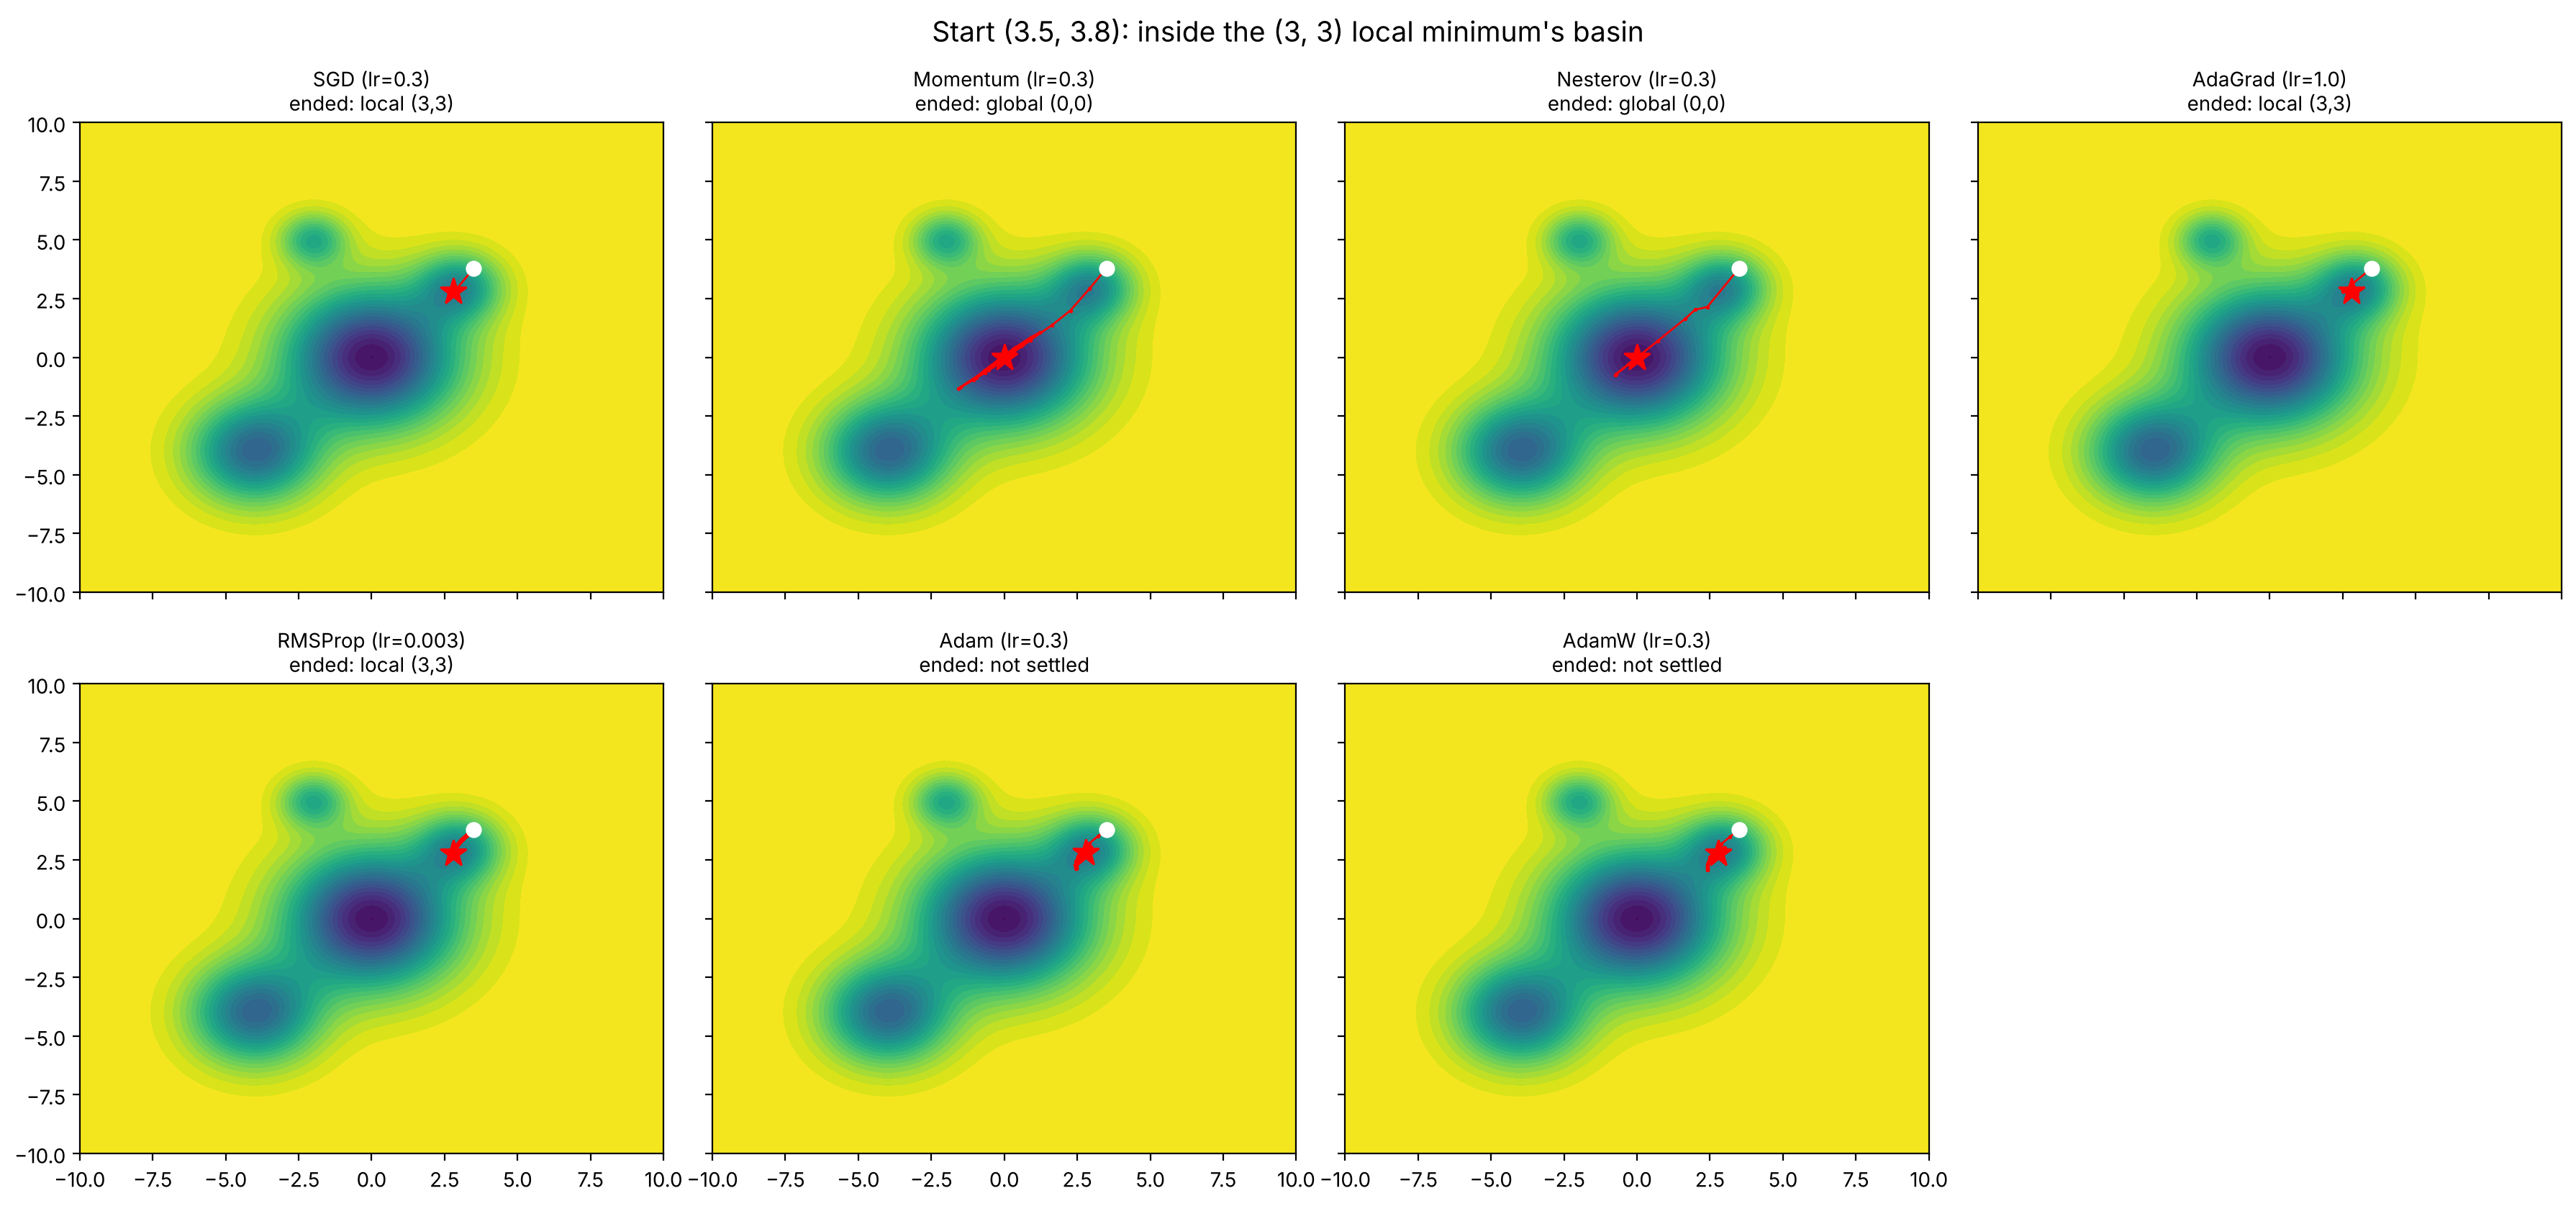

,optimizer,lr,final x,final y,final loss,ended in
0,SGD,0.300,2.793,2.793,-6.213,"local (3,3)"
1,Momentum,0.300,-0.003,-0.003,-10.006,"global (0,0)"
2,Nesterov,0.300,-0.003,-0.003,-10.006,"global (0,0)"
3,AdaGrad,1.000,2.793,2.793,-6.213,"local (3,3)"
4,RMSProp,0.003,2.794,2.791,-6.213,"local (3,3)"
5,Adam,0.300,2.792,2.793,-6.213,not settled
6,AdamW,0.300,2.794,2.791,-6.213,not settled


In [12]:
plot_paths((3.5, 3.8), lrs=BEST_LR, title="Start (3.5, 3.8): inside the (3, 3) local minimum's basin")

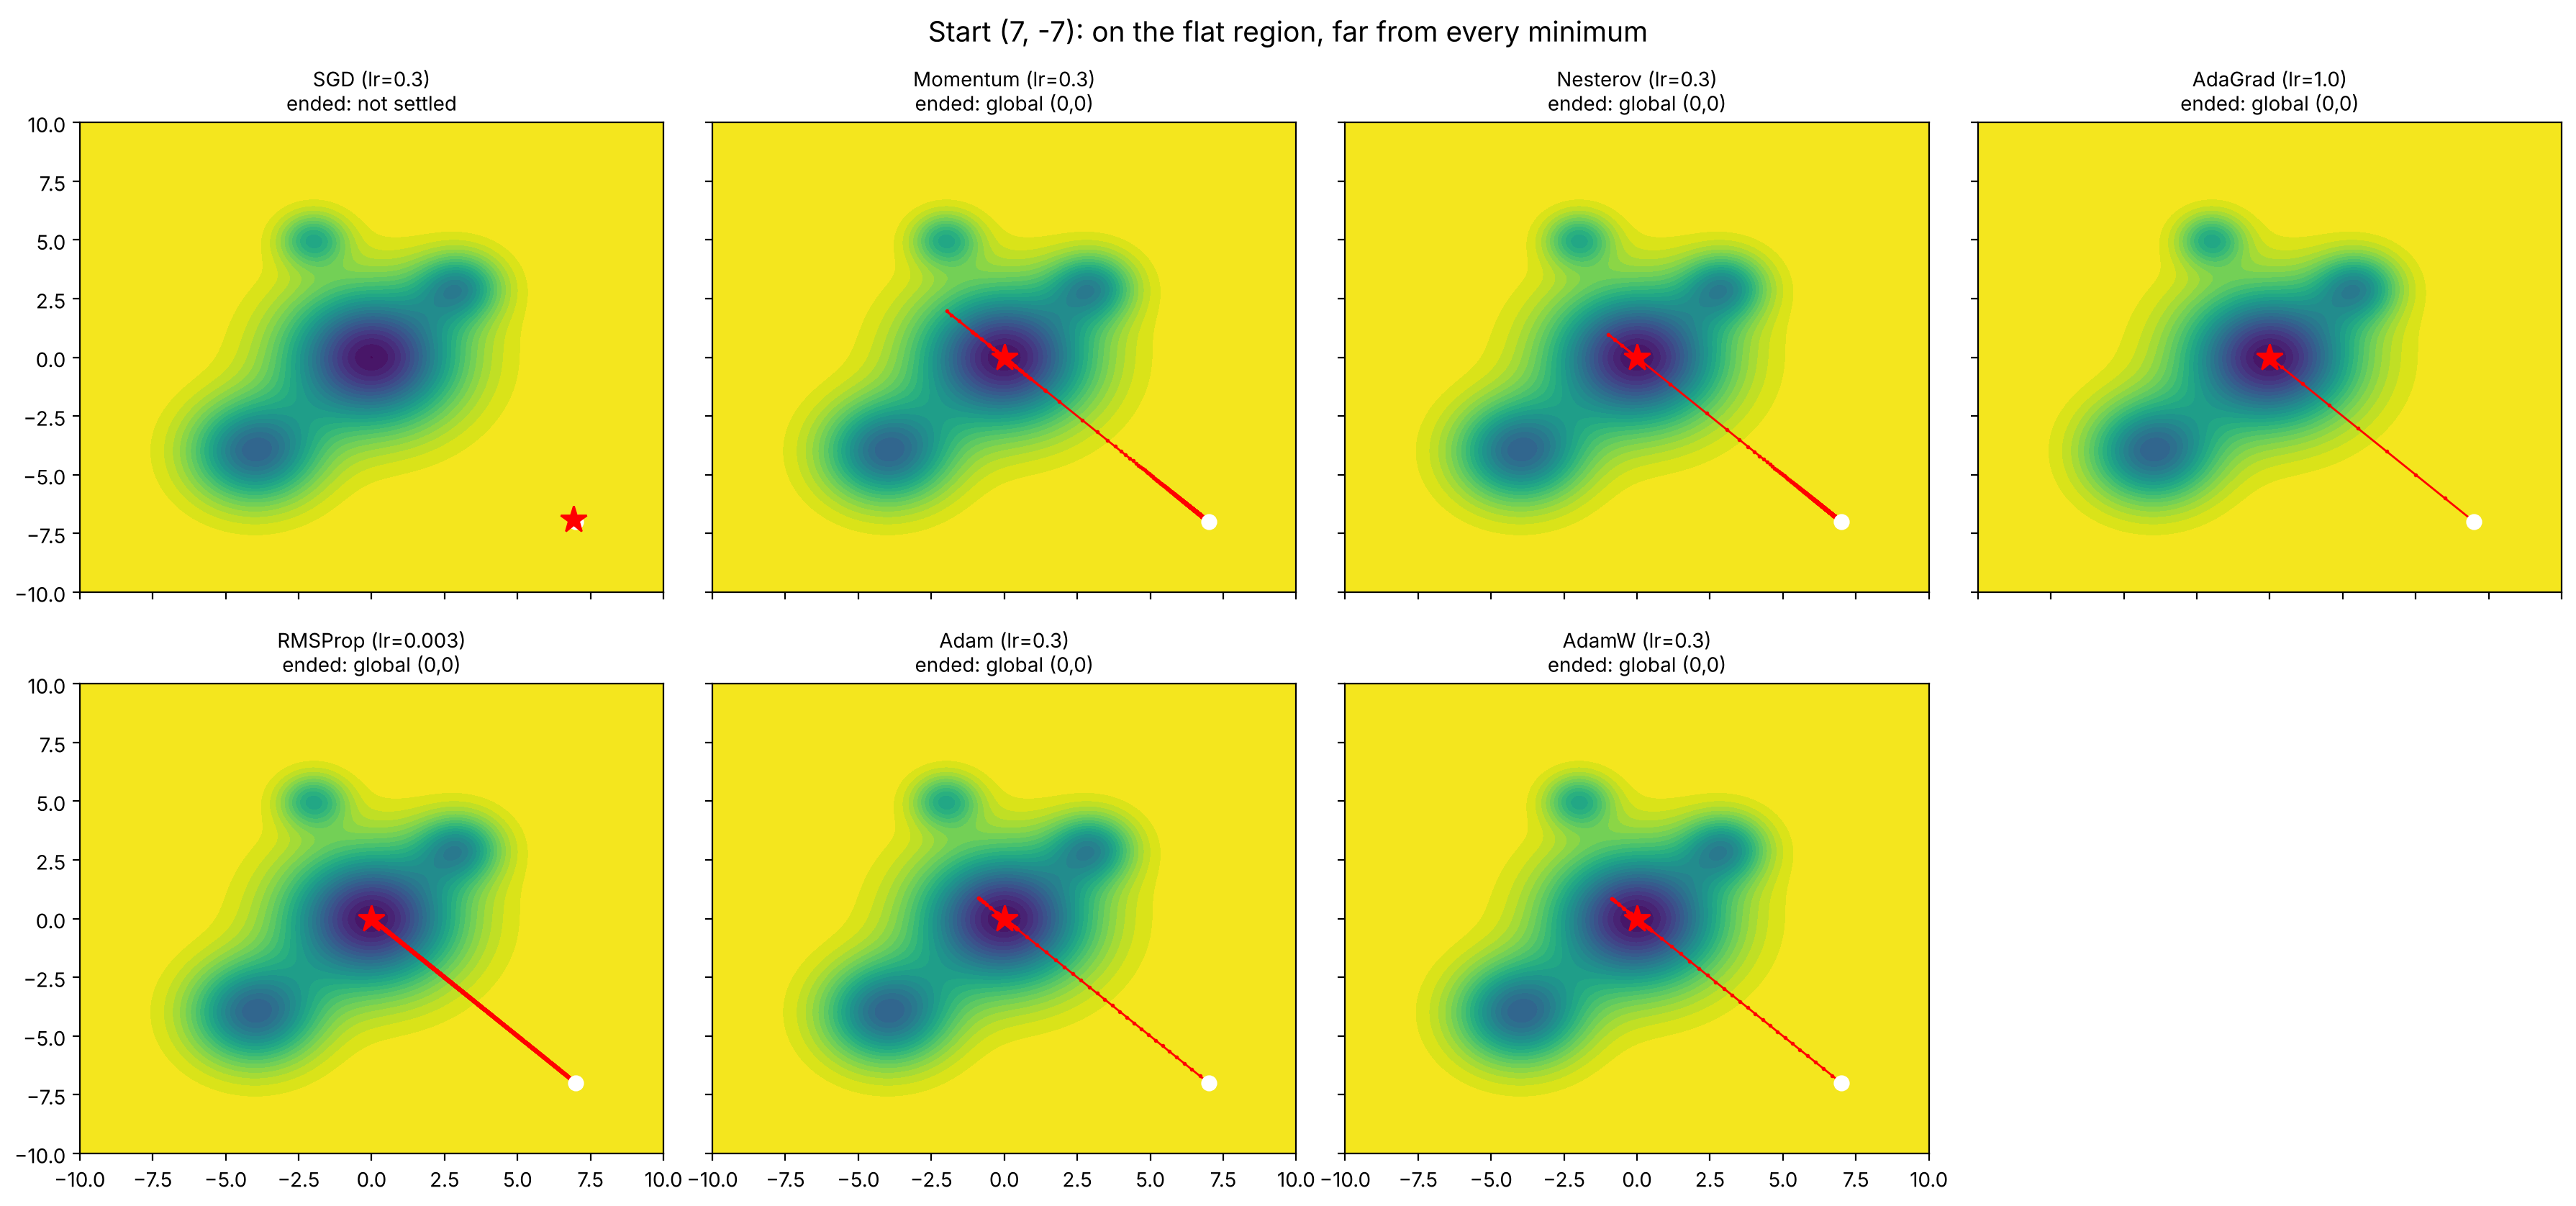

,optimizer,lr,final x,final y,final loss,ended in
0,SGD,0.300,6.913,-6.913,-6.472e-05,not settled
1,Momentum,0.300,-0.003,-0.003,-1.001e+01,"global (0,0)"
2,Nesterov,0.300,-0.003,-0.003,-1.001e+01,"global (0,0)"
3,AdaGrad,1.000,-0.003,-0.003,-1.001e+01,"global (0,0)"
4,RMSProp,0.003,-0.003,-0.003,-1.001e+01,"global (0,0)"
5,Adam,0.300,-0.003,-0.003,-1.001e+01,"global (0,0)"
6,AdamW,0.300,-0.003,-0.003,-1.001e+01,"global (0,0)"


In [13]:
plot_paths((7.0, -7.0), lrs=BEST_LR, title="Start (7, -7): on the flat region, far from every minimum")

## 7. Interactive 3D view

Click optimizer names in the legend to show or hide their paths. Drag to rotate.

In [14]:
def plot_3d(start_xy=(3.5, 3.8), steps=3000, lrs=None):
    lrs = lrs or BEST_LR or DEFAULT_LR
    start = torch.tensor([start_xy], dtype=torch.float64)
    xs3 = torch.linspace(-10, 10, 120, dtype=torch.float64)
    X3, Y3 = torch.meshgrid(xs3, xs3, indexing="xy")
    Z3 = terrain(torch.stack([X3, Y3], -1))
    fig = go.Figure(go.Surface(x=X3, y=Y3, z=Z3, colorscale="Viridis", opacity=0.85, showscale=False))
    for name in SCRATCH:
        path = run_path(SCRATCH[name], start, steps, lr=lrs[name])[::10, 0]
        fig.add_trace(go.Scatter3d(x=path[:, 0], y=path[:, 1], z=terrain(path) + 0.05,
                                   mode="lines+markers", marker=dict(size=2), line=dict(width=5), name=name))
    fig.update_layout(title=f"Optimizer paths from {start_xy}", height=750,
                      scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="loss"))
    fig.show()

plot_3d((3.5, 3.8))

## 8. Summary of results

In [15]:
print("Implementation check: all 7 optimizers match torch.optim within",
      f"{check['max |difference| over 1,000 steps'].max():.1e} over 1,000 steps:", bool(check['matches PyTorch'].all()))
print()
print("Best learning rate per optimizer (441 starts, 3,000 steps):")
for name, r in best.iterrows():
    print(f"  {name:9s} lr={r['lr']:<6} global {r['global %']:5.1f}%  local {r['local %']:5.1f}%  "
          f"stalled {r['stalled %']:5.1f}%  not settled {r['not settled %']:5.1f}%  "
          f"median steps {r['median steps (global runs)']:.0f}")

Implementation check: all 7 optimizers match torch.optim within 1.3e-13 over 1,000 steps: True

Best learning rate per optimizer (441 starts, 3,000 steps):
  SGD       lr=0.3    global  44.0%  local  48.1%  stalled   3.4%  not settled   4.5%  median steps 14
  Momentum  lr=0.3    global  71.9%  local  24.3%  stalled   0.7%  not settled   3.2%  median steps 114
  Nesterov  lr=0.3    global  63.5%  local  21.8%  stalled   0.7%  not settled  14.1%  median steps 18
  AdaGrad   lr=1.0    global  39.0%  local  61.0%  stalled   0.0%  not settled   0.0%  median steps 12
  RMSProp   lr=0.003  global  35.8%  local  63.7%  stalled   0.0%  not settled   0.5%  median steps 1508
  Adam      lr=0.3    global  49.4%  local  24.5%  stalled   0.0%  not settled  26.1%  median steps 116
  AdamW     lr=0.3    global  48.1%  local  24.7%  stalled   0.0%  not settled  27.2%  median steps 113


## 9. Findings

1. **Correctness.** All seven from-scratch optimizers match `torch.optim` to within about $10^{-13}$ over 1,000 steps in float64.
   That's floating-point rounding, so the update rules are implemented exactly.
2. **Momentum was the most reliable at finding the global minimum.** With its best learning rate, it reached the global minimum from **71.9%**
   of starting points, compared with **44.0%** for plain SGD. Built-up velocity carries it over the shallow ridges between basins.
   From (3.5, 3.8), for example, SGD settles in the (3, 3) local minimum while Momentum and Nesterov roll through to the global one.
3. **Nesterov trades some exploration for speed.** Its look-ahead correction brakes earlier, so it escaped fewer local minima (63.5% global)
   but converged much faster (median **18** steps vs. **114** for Momentum).
4. **Adaptive methods never got stuck on flat regions** (0% stalled, vs. 3.4% for SGD). Dividing by the gradient's running size keeps each step
   close to the learning rate, even when the gradient is almost zero.
5. **The same normalization makes adaptive methods jitter near a minimum.** Their steps don't shrink as the gradient shrinks, so at a
   learning rate of 0.3, **26–27%** of Adam and AdamW runs were still moving after 3,000 steps. RMSProp has no momentum to average out the jitter,
   so it only settled reliably at a learning rate of 0.003, and then it took a median of 1,508 steps.
6. **AdaGrad is the opposite.** Its running sum of squared gradients only grows, so its steps keep shrinking. It always settles (0% not settled at learning rates ≥ 0.1),
   but it loses the ability to escape, and 61% of its runs ended in a local minimum.
7. **AdamW ≈ Adam here** (48.1% vs. 49.4% global). Weight decay pulls parameters toward the origin, which happens to be the global minimum on this
   landscape, so any difference between the two is specific to this setup.

**Limits.** This is one synthetic 2D landscape with exact (noise-free) gradients, and the outcomes depend on the 0.01 settling tolerance.
The results show *how* each update rule behaves. They aren't general claims about which optimizer is best for deep learning.